# 01 — Corpus frame and download manifest

**Stage question.** Which conversations, exactly, enter the study, and can that selection be reproduced by anyone from the public dataset?

| | |
|---|---|
| **Purpose** | Turn the public Seamless Interaction metadata into the sampling frame preregistered in `PREREGISTRATION.md`, draw the seeded selection, and write the file that says exactly what to download. |
| **Input** | Four metadata files read at pinned revisions (`configs/corpus.yaml` → `source`): the file index `filelist.csv` from the dataset's code repository, and `interactions.csv`, `participants.csv`, `relationships.csv` from the dataset repository. About 10 MB in total. No audio. |
| **Processing** | Join files to prompts and relationships → apply the frame in its preregistered order → order sessions at random under the recorded seed, keeping one session per speaker → assign roles (pilot, sample, reserve) → measure exact download sizes. |
| **Output** | `manifests/coda_download_manifest.csv` (tracked; one row per participant file). `results/acquisition/`: metadata fetch log with checksums, frame funnel, manifest summary, remote size table, run record. `figures/01_corpus_frame/`. |
| **Scientific assumptions** | Upstream metadata is correct in the fields used: interaction type, relationship, participant identifiers. The dataset documentation reports rare participant-identifier errors and about 10% of interactions with timestamp or prompt-order errors; both are carried as known risks, not corrected here. |
| **Failure modes** | A changed upstream file at a pinned revision (caught by the checksums in the fetch log); an identifier error that silently puts one person in two sessions (not detectable from metadata alone); a selection that differs between runs (checked below against the stored manifest). |
| **What to look at** | The funnel table (every exclusion is counted), the speaker-structure figure (why one session per speaker), the pilot-versus-sample comparison, and the measured download size. |

**Terms used in this notebook.**

- **Session** — one pair of people (a *dyad*) recorded together for about an hour. In this study a session is the *conversation*: the unit of analysis, of resampling and of splitting.
- **Interaction** — one 2–10 minute stretch of talk on one prompt within a session. Adjacent turns are only ever paired inside one interaction.
- **Participant / speaker** — one person, identified by vendor and participant number (`V02_P4059`). Vendors are the recording sites.
- **Stranger dyad** — the two people had not met before the session.
- **Speaker-disjoint** — no person appears in more than one of the training, validation and test sets. Evaluating on people never seen in training is what makes a result about speakers in general rather than about these speakers.
- **Manifest** — the list of files to download, in a fixed order, with their roles. It is the reproducible definition of the sample.
- **Seed** — the number that fixes a random draw so that it comes out identically every time.

In [1]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   13.4 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint 51ce4acb032a1d84
artifacts      manifest=True, metadata=True, transcripts=False, turns=False, audio_pass_sessions=0, channel_qc=False


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [2]:
# Parameters
RUN_FROM_SCRATCH = False      # True: re-fetch metadata and rebuild the manifest even if present
MEASURE_EXACT_SIZES = True    # HEAD request per file for the roles below (no download)
SIZE_ROLES = ['pilot']        # add 'sample' before the full run

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import paths
from src.data import seamless as S
from src.runtime import write_run_record
from src.viz import style

P = paths().ensure()
CFG = P.load_config('corpus')
OUT = P.results / 'acquisition'
OUT.mkdir(parents=True, exist_ok=True)
style.apply()

def rel(p):
    """Paths in tracked logs are stored relative to the project root."""
    try:
        return Path(p).resolve().relative_to(P.root.resolve()).as_posix()
    except ValueError:
        return str(p)

print('corpus          ', CFG['corpus'])
print('dataset revision', CFG['source']['hf_revision'])
print('index commit    ', CFG['source']['github_commit'])
print('selection seed  ', CFG['selection_seed'])

corpus           seamless_naturalistic
dataset revision ba9e212ab927ba05bfd80778f53bf9de69f65e3b
index commit     b61b0324461f05221659cc38a1130f854fdd2855
selection seed   20260912


## 1. Metadata at pinned revisions

Every metadata file is read from a fixed commit rather than from "latest", so the sampling frame cannot change under the study if the upstream repositories are updated. The SHA-256 checksum of each file is logged; a rerun that produces a different checksum means the source changed and the selection must not be trusted until that is explained.

In [4]:
rows = []
for name, url in S.metadata_urls(CFG['source']).items():
    dest = P.raw_metadata / name
    if RUN_FROM_SCRATCH:
        dest.unlink(missing_ok=True)
    rows.append({'file': name, **S.fetch(url, dest)})
meta_log = pd.DataFrame(rows)
meta_log['path'] = meta_log['path'].map(rel)
meta_log.to_csv(OUT / 'metadata_fetch_log.csv', index=False)
meta_log[['file', 'status', 'bytes', 'sha256', 'url']]

,file,status,bytes,sha256,url
0,filelist.csv,exists,7334574,e8ecdfd690286502193489b638208b70d1834dc3e25e21...,https://raw.githubusercontent.com/facebookrese...
1,interactions.csv,exists,1471780,af692f173b346fb3c0985ecce64eb0f6602d7958d3fdd9...,https://huggingface.co/datasets/facebook/seaml...
2,participants.csv,exists,311062,99c418c97e768092e128b96978bf8656b1e599c1c4950c...,https://huggingface.co/datasets/facebook/seaml...
3,relationships.csv,exists,141286,aa5b272864a55cbddb51da1e5b5467c2f1353fdf897fed...,https://huggingface.co/datasets/facebook/seaml...


## 2. What the corpus contains

The naturalistic partition only. The improvised partition uses professional actors and is outside the design.

In [5]:
frame = S.load_frame(P.raw_metadata)
overview = pd.Series({
    'sessions (dyads)': frame['session_key'].nunique(),
    'interactions': frame['interaction_key'].nunique(),
    'participants': frame['participant_key'].nunique(),
    'participant files': len(frame),
    'vendors (recording sites)': frame['vendor_id'].nunique(),
}, name='naturalistic partition')
by_type = frame.drop_duplicates('interaction_key')['interaction_type'].value_counts()
by_rel = frame.drop_duplicates('session_key')['relationship'].fillna('not recorded').value_counts()
display(overview.to_frame())
display(by_type.to_frame('interactions'))
display(by_rel.to_frame('sessions'))

,naturalistic partition
sessions (dyads),3325
interactions,46810
participants,3498
participant files,93620
vendors (recording sites),4


,interactions
interaction_type,
ipc_conversation,37661
grounded_gesture,5687
collaborative_storytelling,2305
charades,1157


,sessions
relationship,
familiar,1701
stranger,1576
not recorded,48


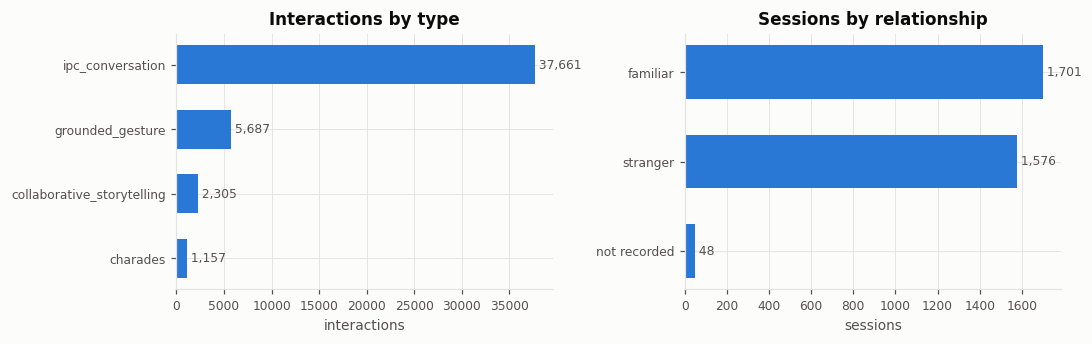

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ax = axes[0]
ax.barh(by_type.index[::-1], by_type.values[::-1], color=style.SERIES[0], height=0.6)
ax.set_title('Interactions by type')
ax.set_xlabel('interactions')
for y, v in enumerate(by_type.values[::-1]):
    ax.text(v, y, f' {v:,}', va='center', fontsize=8, color=style.INK_SECONDARY)
ax = axes[1]
ax.barh(by_rel.index[::-1], by_rel.values[::-1], color=style.SERIES[0], height=0.6)
ax.set_title('Sessions by relationship')
ax.set_xlabel('sessions')
for y, v in enumerate(by_rel.values[::-1]):
    ax.text(v, y, f' {v:,}', va='center', fontsize=8, color=style.INK_SECONDARY)
fig.tight_layout()
style.save(fig, P.figures, '01_corpus_frame', 'corpus_composition')
plt.show()

**What is plotted.** Left: interactions in the naturalistic partition by task type. Right: sessions by the recorded relationship between the two participants.

**Why it matters.** CODA asks about delivery in conversation. Only `ipc_conversation` is conversation: the other types are games — acting out a sentence with one word emphasised, charades, and building a story one sentence each — where the task dictates delivery or turn order. The relationship split shows the size of the stranger-only frame, which matches the population the design was drawn up for.

**What would indicate a problem.** A type or relationship category missing entirely, or counts far from the published totals (about 3,300 naturalistic sessions), would mean the join to the metadata failed.

**Conclusion.** Conversation is by far the largest type, and stranger sessions are about half of all sessions. The frame below is large relative to the 250 sessions needed.

## 3. The sampling frame, applied in its preregistered order

Each exclusion is applied in the order written in the preregistration, and the count after each step is kept. An exclusion that is not counted cannot be defended.

**Manner-instructing prompts.** A few conversation prompts tell participants *how* to speak ("speak in a firm, confrontational tone"; role-play prompts that assign a style to each person). If both people's delivery is set by the prompt, their deliveries will be related for a reason that has nothing to do with one responding to the other. Those interactions are removed by a fixed rule (`configs/corpus.yaml` → `frame`); the prompts it catches are listed below so the rule can be checked by eye.

In [7]:
eligible, funnel = S.apply_frame(frame, CFG['frame'])
funnel.to_csv(OUT / 'frame_funnel.csv', index=False)
display(funnel)

stranger_ipc = frame[(frame['relationship'] == CFG['frame']['relationship'])
                     & frame['interaction_type'].isin(CFG['frame']['interaction_types'])]
flag = S.manner_instructing(stranger_ipc, CFG['frame']['exclude_prompt_text_regex'],
                            CFG['frame']['exclude_two_sided_role_prompts'])
excluded = (stranger_ipc[flag].drop_duplicates('interaction_key')
            .groupby(['prompt_id_unique', 'participant_a_prompt_text']).size()
            .rename('interactions').reset_index()
            .sort_values('interactions', ascending=False))
excluded['participant_a_prompt_text'] = excluded['participant_a_prompt_text'].str.slice(0, 110)
excluded.to_csv(OUT / 'excluded_manner_prompts.csv', index=False)
excluded.head(15)

,stage,sessions,interactions,files
0,"naturalistic, all",3325,46810,93620
1,relationship == stranger,1576,22582,45164
2,interaction type in ipc_conversation,1576,17935,35870
3,manner-instructing prompts removed,1576,17771,35542
4,both participants present,1576,17771,35542


,prompt_id_unique,participant_a_prompt_text,interactions
4,P0004_EO_ANCP_XXXX,"Ask your partner: ""Would you rather always hav...",140
3,P0004_EO_ANCP_APCP,"Ask your partner: ""Would you rather always hav...",2
5,P0005_EO_ANCP_AMCP,"Ask your partner: ""Would you rather go into th...",2
10,P0018_MN_AMCP_AMCN,Share an embarrassing story about yourself wit...,2
14,P0031_DN_APCM_AMCP,Think of a time that you had to give difficult...,2
18,P0048_CC_ANCP_APCN,You will each see the same prompt:\n\nDiscuss ...,2
8,P0016_MP_AMCN_APCP,Recall a time that you were stuck in life or o...,2
2,P0003_EO_ANCP_AMCN,Ask your partner whether they'd rather be able...,1
1,P0002_DP_APCP_AMCM,Ask your partner what they truly want in life....,1
0,P0001_DN_AMCM_AMCM,Ask your partner about a topic for which you h...,1


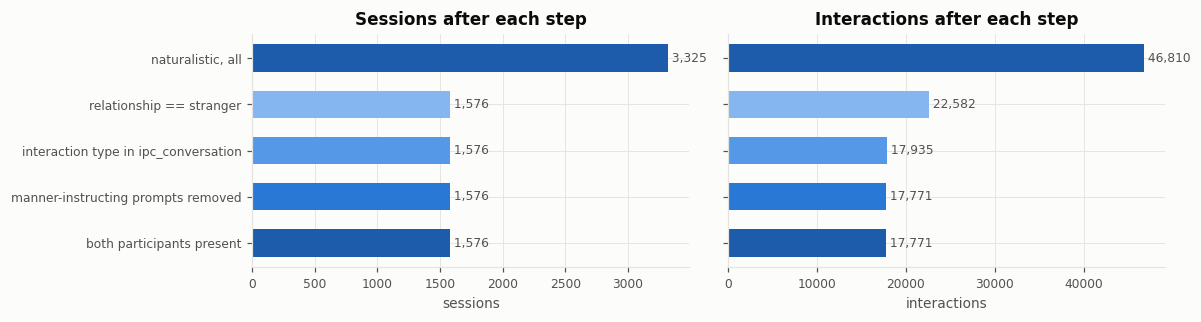

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)
labels = funnel['stage'][::-1]
colours = list(style.SEQUENTIAL[::2])[:len(funnel)][::-1]
for ax, col in zip(axes, ['sessions', 'interactions']):
    vals = funnel[col][::-1].to_numpy()
    ax.barh(labels, vals, color=colours, height=0.6)
    for y, v in enumerate(vals):
        ax.text(v, y, f' {v:,}', va='center', fontsize=8, color=style.INK_SECONDARY)
    ax.set_title(col.capitalize() + ' after each step')
    ax.set_xlabel(col)
fig.tight_layout()
style.save(fig, P.figures, '01_corpus_frame', 'frame_funnel')
plt.show()

**What is plotted.** The number of sessions (left) and interactions (right) remaining after each preregistered step, read from the bottom up.

**Why it matters.** It is the first stage of the sample-attrition record the report must carry: from the whole corpus to the frame the random selection is drawn from.

**What would indicate a problem.** A step that removes most of the corpus unexpectedly, or a manner-prompt rule that catches prompts which do not instruct delivery (check the table above).

**Conclusion.** The relationship step removes about half the sessions; the task-type and prompt rules remove interactions but no whole session, since every stranger session contains conversation interactions.

## 4. Why one session per speaker

People in this corpus could take part in several sessions, with different partners. That links sessions into chains: if person *a* talked with *b*, and *b* later with *c*, then a speaker-disjoint split must put all three sessions in the same set. The figure below shows how many sessions each person in the frame took part in, and how large those chains get.

people in the frame: 1,772
people in more than one session: 533 (30.1%)
largest chain of linked sessions: 393 of 1,576 sessions (24.9%)


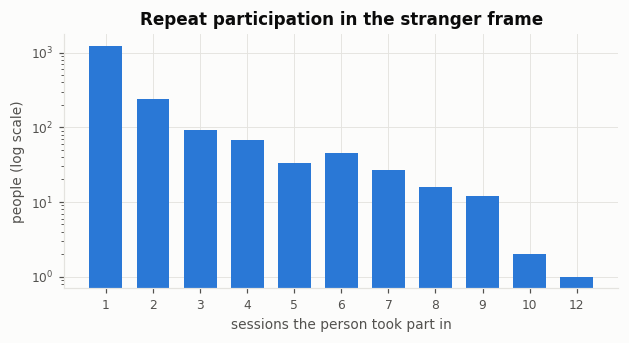

In [9]:
per_person = eligible.groupby('participant_key')['session_key'].nunique()
comp = S.speaker_components(eligible)
comp_sizes = comp.value_counts()
print(f"people in the frame: {per_person.size:,}")
print(f"people in more than one session: {(per_person > 1).sum():,} ({(per_person > 1).mean():.1%})")
print(f"largest chain of linked sessions: {comp_sizes.iloc[0]:,} of {comp.size:,} sessions "
      f"({comp_sizes.iloc[0] / comp.size:.1%})")

counts = per_person.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.bar(counts.index.astype(str), counts.values, color=style.SERIES[0], width=0.7)
ax.set_yscale('log')
ax.set_xlabel('sessions the person took part in')
ax.set_ylabel('people (log scale)')
ax.set_title('Repeat participation in the stranger frame')
style.save(fig, P.figures, '01_corpus_frame', 'repeat_participation')
plt.show()

**What is plotted.** For every person in the stranger frame, the number of sessions they took part in. The vertical axis is logarithmic because most people appear once.

**Why it matters.** Splitting by linked groups would force the largest group — a sizeable share of the frame — into a single split, making a 70/10/20 division lumpy and uncontrollable. Selecting at most one session per person instead makes every split of sessions automatically speaker-disjoint, and mirrors the design's original corpus, where people rarely recur.

**What would indicate a problem.** A person listed in many sessions in one site could also be an identifier error (the dataset documentation reports rare cases); the one-session rule limits the damage either way.

**Conclusion.** Repeat participation is common enough that it must be handled explicitly; the one-session rule handles it at the cost of the sessions it skips, which the selection below reports.

## 5. The seeded selection and the manifest

Sessions are put in random order under the recorded seed. Walking that order, a session is accepted only if neither participant was accepted before. The first 40 accepted form the **pilot** (the gate-G0 sample and the development subset); the next 210 complete the **sample** of 250; the rest are the **reserve**, used in order only to replace sessions that fail channel quality control. Walking a random order and replacing failures with the next session is exactly a random selection among sessions that pass quality control.

If a manifest already exists, the rebuilt one must be identical to it. That is the reproducibility check: the same public metadata and the same seed always give the same people in the same order.

In [10]:
order = S.speaker_unique_order(eligible, CFG['selection_seed'])
manifest = S.build_manifest(eligible, order, CFG['pilot_n_conversations'],
                            CFG['n_conversations'], CFG['source']['file_base_url'])
print(f"sessions accepted in order: {len(order):,} of {eligible['session_key'].nunique():,} in the frame")

if P.manifest.exists() and not RUN_FROM_SCRATCH:
    stored = pd.read_csv(P.manifest, dtype=str)
    same = stored.astype(str).equals(manifest.astype(str))
    print('stored manifest reproduced exactly:', same)
    assert same, 'The rebuilt manifest differs from the stored one. Do not continue until explained.'
else:
    manifest.to_csv(P.manifest, index=False)
    print('manifest written:', rel(P.manifest))

summary = (manifest.groupby('role')
           .agg(sessions=('session_key', 'nunique'), interactions=('interaction_key', 'nunique'),
                speakers=('participant_key', 'nunique'), files=('file_id', 'size'))
           .reindex(['pilot', 'sample', 'reserve']))
summary.to_csv(OUT / 'manifest_summary.csv')
summary

sessions accepted in order: 724 of 1,576 in the frame
stored manifest reproduced exactly: True


,sessions,interactions,speakers,files
role,,,,
pilot,40,458,80,916
sample,210,2425,420,4850
reserve,474,5470,948,10940


**Reading the table.** Each accepted session contributes two speakers, so speakers are exactly twice the sessions in every role: no one is shared between sessions. Every file row names one participant's side of one interaction; the manifest carries the three download addresses for it (audio, transcript, voice-activity segments) and nothing else — video and motion features are never requested.

## 6. Is the pilot representative?

The pilot is used for all development work and for gate G0, so it should resemble the sample it stands in for on the characteristics that matter to the experiment. Two are available before any audio is touched: the recording site, which carries differences in recording quality, and the number of conversation interactions per session, which drives how many turn pairs a session yields.

vendor_id,00,01,02,03
role,,,,
pilot,8%,10%,30%,52%
sample,13%,12%,21%,54%
reserve,11%,16%,10%,62%


,count,mean,std,min,25%,50%,75%,max
role,,,,,,,,
pilot,40.0,11.4,3.4,6.0,8.0,12.0,14.0,16.0
sample,210.0,11.5,3.5,1.0,9.0,12.0,14.0,17.0
reserve,474.0,11.5,3.2,1.0,9.0,12.0,14.0,17.0


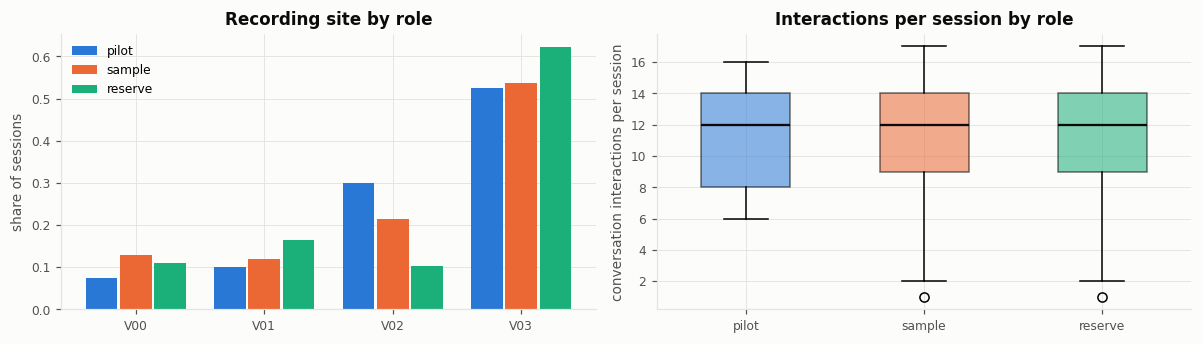

In [11]:
sess = manifest.drop_duplicates('session_key')[['session_key', 'role', 'vendor_id']].copy()
sess = sess.merge(manifest.groupby('session_key')['interaction_key'].nunique().rename('interactions'),
                  on='session_key')
roles = ['pilot', 'sample', 'reserve']
vendor_share = (sess.groupby('role')['vendor_id'].value_counts(normalize=True)
                .unstack(fill_value=0).reindex(roles))
display(vendor_share.style.format('{:.0%}'))
display(sess.groupby('role')['interactions'].describe().reindex(roles).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
vendors = list(vendor_share.columns)
w = 0.8 / len(roles)
for i, r in enumerate(roles):
    ax.bar(np.arange(len(vendors)) + i * w, vendor_share.loc[r], width=w - 0.02,
           color=style.SERIES[i], label=r)
ax.set_xticks(np.arange(len(vendors)) + w, [f'V{v}' for v in vendors])
ax.set_ylabel('share of sessions')
ax.set_title('Recording site by role')
ax.legend()
ax = axes[1]
data = [sess.loc[sess['role'] == r, 'interactions'] for r in roles]
bp = ax.boxplot(data, widths=0.5, patch_artist=True,
                medianprops={'color': style.INK, 'linewidth': 1.5})
ax.set_xticks(range(1, len(roles) + 1), roles)
for patch, c in zip(bp['boxes'], style.SERIES):
    patch.set_facecolor(c)
    patch.set_alpha(0.55)
ax.set_ylabel('conversation interactions per session')
ax.set_title('Interactions per session by role')
fig.tight_layout()
style.save(fig, P.figures, '01_corpus_frame', 'pilot_representativeness')
plt.show()

**What is plotted.** Left: the share of sessions from each recording site in the pilot, the rest of the sample, and the reserve. Right: the distribution of conversation interactions per session in each role.

**Why it matters.** If the pilot came mostly from one site, a quality problem specific to that site would either be missed by G0 or be over-weighted. If pilot sessions were systematically shorter or longer, the pair-yield estimate from the pilot would not transfer to the sample.

**What would indicate a problem.** A site share, or an interaction distribution, that differs from the sample by more than drawing 40 sessions at random would produce. For a share *p*, the standard error over 40 sessions is √(p(1−p)/40) — about 8 percentage points at p = 0.5 — so differences of that order are expected by chance. This is a descriptive check with no pass mark.

**Conclusion.** Record here whether the pilot looks like the sample. It is not resized if it does not (the pilot's size is fixed by the G0 protocol); a visible difference is carried into the G0 interpretation instead.

## 7. Exact download size, before downloading

Each file's size is asked of the file server without downloading it (an HTTP `HEAD` request). This turns the storage estimate into a measurement and reveals any file that is missing upstream before the audio pass depends on it.

In [12]:
if MEASURE_EXACT_SIZES:
    sub = manifest[manifest['role'].isin(SIZE_ROLES)]
    urls = pd.concat([sub['audio_url'], sub['transcript_url'], sub['vad_url']]).tolist()
    sizes = S.remote_sizes(urls)
    sizes['kind'] = np.select([sizes['url'].str.endswith('.wav'),
                               sizes['url'].str.contains('/transcript/')],
                              ['audio', 'transcript'], default='vad')
    tag = '_'.join(SIZE_ROLES)
    sizes.to_csv(OUT / f'remote_sizes_{tag}.csv', index=False)
    table = sizes.groupby('kind').agg(files=('url', 'size'), missing=('exists', lambda s: int((s == False).sum())),
                                      unknown=('exists', lambda s: int(s.isna().sum())),
                                      gigabytes=('bytes', lambda b: b.sum() / 1e9))
    display(table.round(3))
    audio_gb = table.loc['audio', 'gigabytes']
    print(f"audio to stream for {tag}: {audio_gb:.1f} GB — streamed to the runtime's local disk, "
          f"measured, and deleted interaction by interaction; never stored on Drive.")
    print(f"largest single audio file: {sizes.loc[sizes['kind'] == 'audio', 'bytes'].max() / 1e6:.0f} MB")

,files,missing,unknown,gigabytes
kind,,,,
audio,916,0,0,36.256
transcript,916,0,0,0.026
vad,916,0,0,0.002


audio to stream for pilot: 36.3 GB — streamed to the runtime's local disk, measured, and deleted interaction by interaction; never stored on Drive.
largest single audio file: 386 MB


**Reading the size table.** *Audio* is what the audio pass (notebook 03) streams; at any moment only the two files of one interaction per worker are on disk. *Transcript* and *vad* are the small text files that notebook 02 keeps on Drive. A non-zero *missing* count names files the manifest expects but the server does not have; their interactions will fail channel quality control as `missing` rather than being silently skipped.

In [13]:
rec = write_run_record(OUT / '01_run_record.json', '01_corpus_frame_and_manifest', {
    'source': CFG['source'],
    'selection_seed': CFG['selection_seed'],
    'manifest_sha256': S.sha256_file(P.manifest),
    'sessions_in_frame': int(eligible['session_key'].nunique()),
    'sessions_accepted': len(order),
    'roles': summary.to_dict(orient='index'),
})
print('run record written; manifest sha256', rec['manifest_sha256'][:16])

run record written; manifest sha256 7649270421ecc3ef


## Summary

- The sample is defined entirely by public metadata at pinned revisions, a recorded seed and a fixed rule. The manifest is regenerated identically on every run, and the check above fails loudly if it is not.
- Every exclusion between the whole corpus and the selectable frame is counted (`results/acquisition/frame_funnel.csv`).
- One session per speaker makes splits speaker-disjoint by construction.
- The pilot's representativeness on recording site and session length is shown before any audio is processed.

**What this stage does not establish.** Whether the audio of the selected sessions is usable, how many turn pairs they yield, or whether prosody can be measured on them. Those are notebooks 02–04.

**Next.** `02_transcripts_and_turns`: fetch the transcripts and voice-activity segments for the pilot and build turns and candidate pairs.